### REFERENCES
 * https://claude.ai
 * https://chatgpt.com

# Problem Framing

> ## Main goal
 > The goal of this challenge is to predict the probability that a farmer will adopt a practice after their first training session delivered by DigiCow. The predictions must be based on data that would be available at the time of the training event. Accurately predicting adoption can help DigiCow:
> * Prioritise follow‑up support for farmers who are most likely to adopt new practices.
> * Tailor extension services and advice based on predicted adoption likelihood.
> * Improve training programmes to increase real‑world impact over time.

> ## Dataset and prediction task
> You are given a dataset where each row represents a farmer’s first training event and a set of features that describe the farmer and their context at that time. The task is to build a model that outputs the following:
> * Probability of adoption within 7 days
> * Probability of adoption within 90 days
> * Probability of adoption within 120 days
>  
> The model must learn from information that a farmer would realistically have at the time of their training—features that occur after these time horizons or leak future information should be avoided.

> ## Can we solve it without ML?
> Traditional rule‑based systems (e.g. simple thresholds on farmer age or location) are limited and cannot reliably model the complex patterns underlying farmer behaviour. In contrast, machine learning models allow us to:
> 
> * Capture complex, non‑linear relationships: Farmer adoption decisions are influenced by many interacting factors (e.g., experience, training type, prior behaviours). ML captures these patterns automatically from data.
> * redict probabilities rather than hard classes: The evaluation favours probability outputs (not just yes/no predictions), and many ML models excel at producing well‑calibrated probability estimates.
> * Generalise to new examples: Unlike static rules, machine learning adapts to unseen data, making it more reliable when applied to new sets of farmers or changing contexts.
> * Handle imbalanced outcomes: Since adoption might be rarer than non‑adoption, ML models can be tuned to deal with class imbalance and still learn meaningful patterns.


> ## Technical formulation
> 
> * Problem type: Supervised Machine Learning
> * Task type: Task type: Multi‑label classification with probabilistic outputs
> * Input features (X): Processed features representing farmer demographics, training details, and other relevant variables known at training time
> * Output (y): Three probability scores (for adoption within 7, 90 and 120 days respectively)
> * 
> The challenge uses a multi‑metric evaluation, where your model’s performance is assessed using:
> * Log Loss (75%) – Encourages models to give reliable probability estimates. Predictions that are confidently wrong are penalised heavily.
> * ROC‑AUC (25%) – Measures how well the model ranks true adopters above non‑adopters across thresholds, which is especially valuable when the data is imbalanced.
> 
> **Metric :** 0.75 × (1 − LogLoss) + 0.25 × ROC-AUC
>
> The final score is a weighted average of these metrics across all three adoption horizons (7, 90 and 120 days).

## 0. Setup — Imports & Configuration

In [1]:
import os
import pandas as pd
import numpy as np
import ast
import warnings
import multiprocessing
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import log_loss, roc_auc_score, f1_score
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import (HistGradientBoostingClassifier,
                               RandomForestClassifier,
                               ExtraTreesClassifier)
from scipy.stats import entropy as scipy_entropy
from joblib import Parallel, delayed

USE_LGBM     = False
USE_XGB      = False
USE_CATBOOST = False
USE_OPTUNA   = False

try:
    import lightgbm as lgb;   USE_LGBM   = True
    print("LightGBM imported")
except ImportError:                                 
    print("LightGBM not imported")
try:
    import xgboost as xgb;    USE_XGB    = True
    print("XGBoost imported")
except ImportError:                                 
    print("XGBoost not imported")
try:
    from catboost import CatBoostClassifier
    USE_CATBOOST = True
    print("CatBoost imported")
except ImportError:                                 
    print("CatBoost not imported")
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    USE_OPTUNA = True;                              
    print("Optuna imported")
except ImportError:                                 
    print("Optuna not imported")

# ── GPU detection ─────────────────────────────────────────────────────────────
USE_GPU = False
GPU_DEVICE_LGBM = 'cpu'
GPU_DEVICE_XGB  = 'hist'
GPU_DEVICE_CB   = 'CPU'

try:
    import subprocess
    result = subprocess.run(['nvidia-smi'], capture_output=True, timeout=3)
    if result.returncode == 0:
        USE_GPU = False
        GPU_DEVICE_LGBM = 'cpu'
        GPU_DEVICE_XGB  = 'hist'
        GPU_DEVICE_CB   = 'CPU'
        print("NVIDIA GPU detected")
    else:
        print("No NVIDIA GPU — using CPU")
except Exception:
    print("No NVIDIA GPU — using CPU")

# ── Global hyperparameters ────────────────────────────────────────────────────
N_SPLITS         = 10
N_OPTUNA_TRIALS  = 50
OPTUNA_CV_SPLITS = 5
OPTUNA_N_JOBS    = -1
CV_N_JOBS        = -1
PSEUDO_THR_HI    = 0.90   # conservative high threshold for pseudo-labeling
PSEUDO_THR_LO    = 0.01   # conservative low threshold for pseudo-labeling
USE_PSEUDO       = True
TOP_K_FEATURES   = 150    # top features to keep after selection

if USE_GPU:
    CV_N_JOBS = 1
    print("  → Sequential CV (GPU mode)")
else:
    N_CPU = multiprocessing.cpu_count()
    print(f"  → Parallel CV on {N_CPU} CPUs")

# Mapping from short names to full target column names
SHORT_TO_TARGET = {
    '07':  'adopted_within_07_days',
    '90':  'adopted_within_90_days',
    '120': 'adopted_within_120_days',
}
SHORT_MAP = [('07','adopted_within_07_days'),
             ('90','adopted_within_90_days'),
             ('120','adopted_within_120_days')]

# Keyword groups for topic categorization
TOPIC_KEYWORDS = {
    'dairy':   ['dairy','milk','cow','calf','lactating','calving','unga','transition'],
    'poultry': ['poultry','chicken','layer','broiler','kienyeji','egg','hatch'],
    'crop':    ['maize','bean','seed','fertilizer','weed','pest','crop','asili'],
    'health':  ['health','vaccine','vaccin','biosecurity','disease','ppe','hygiene'],
    'digital': ['app','ndume','record','digital'],
    'feeding': ['feeding','feed','nutrition','tyari'],
    'housing': ['housing','house','shed','pen','cage'],
    'finance': ['finance','saving','loan','credit','insurance'],
}

LightGBM imported
XGBoost imported
CatBoost imported
Optuna imported
No NVIDIA GPU — using CPU
  → Parallel CV on 8 CPUs


## 1. Data Loading & Exploratory Data Analysis (EDA)

In [2]:
# Load all datasets
data_path = './'
train  = pd.read_csv(f'{data_path}Train.csv')
test   = pd.read_csv(f'{data_path}Test.csv')
prior  = pd.read_csv(f'{data_path}Prior.csv')
sample = pd.read_csv(f'{data_path}SampleSubmission.csv')

print(f"Train shape : {train.shape}")
print(f"Test shape  : {test.shape}")
print(f"Prior shape : {prior.shape}")
print(f"Sample shape: {sample.shape}")

Train shape : (13536, 17)
Test shape  : (5621, 14)
Prior shape : (44882, 17)
Sample shape: (5621, 7)


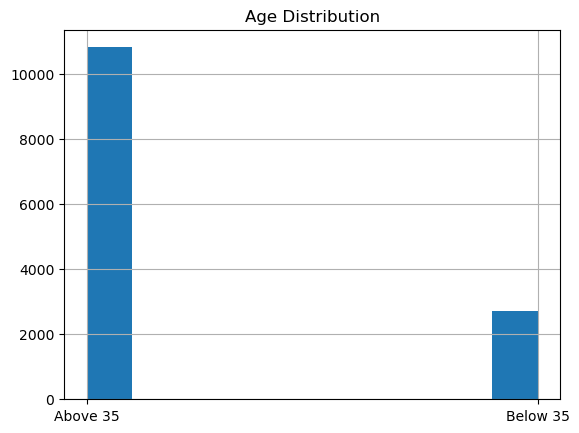

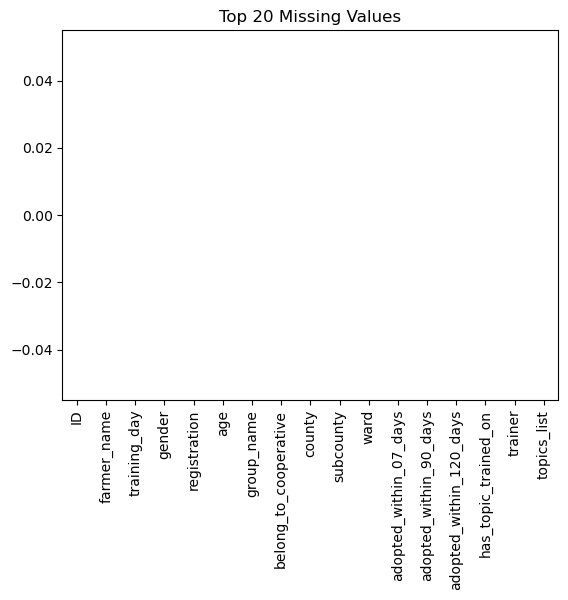

In [3]:
if 'train' in globals():
    # Plot target distribution (7 days if exists)
    if 'Target_07' in train.columns:
        plt.figure()
        train['Target_07'].value_counts().plot(kind='bar')
        plt.title('Distribution of Target_07')
        plt.show()

    # Plot age distribution if exists
    if 'age' in train.columns:
        plt.figure()
        train['age'].hist()
        plt.title('Age Distribution')
        plt.show()

    # Missing values overview
    plt.figure()
    train.isnull().sum().sort_values(ascending=False).head(20).plot(kind='bar')
    plt.title('Top 20 Missing Values')
    plt.show()


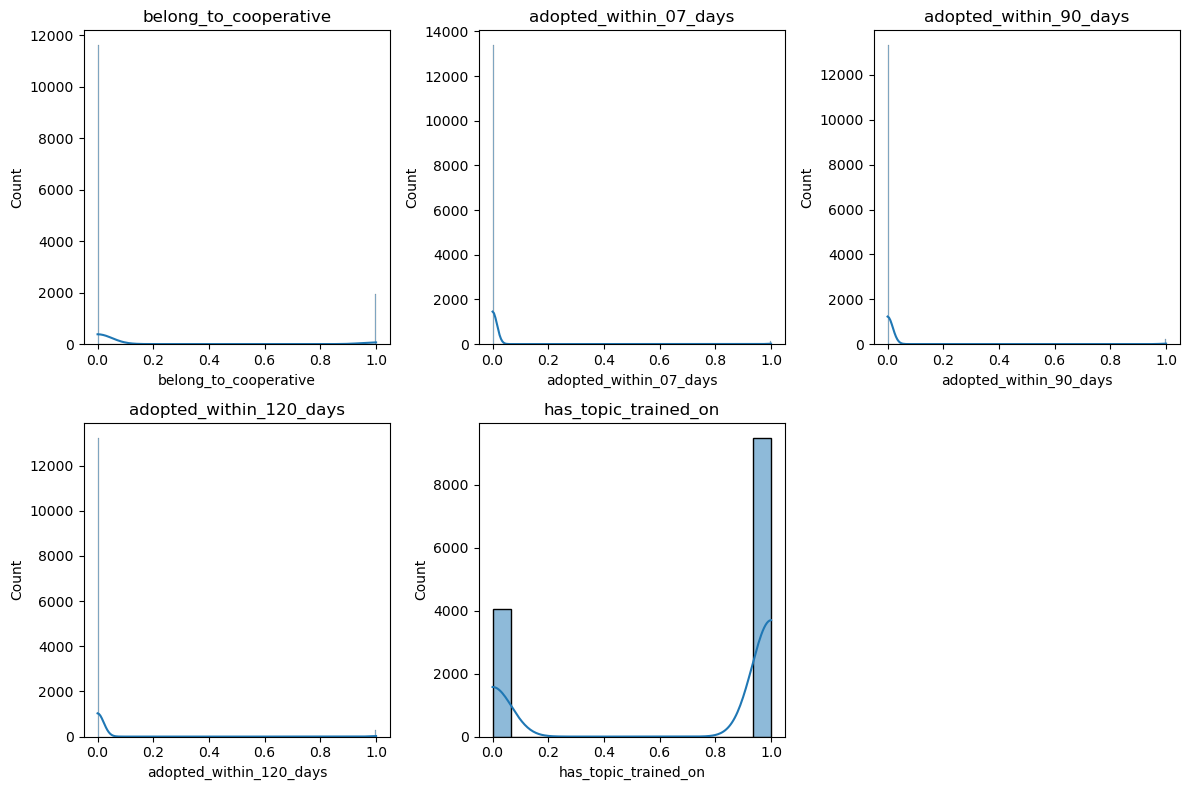

In [4]:
num_cols = train.select_dtypes(include=['int64','float64']).columns

plt.figure(figsize=(12,8))
for i, col in enumerate(num_cols[:6]):
    plt.subplot(2,3,i+1)
    sns.histplot(train[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

In [5]:
# Preview training data
train.head()

,ID,farmer_name,training_day,gender,registration,age,group_name,belong_to_cooperative,county,subcounty,ward,adopted_within_07_days,adopted_within_90_days,adopted_within_120_days,has_topic_trained_on,trainer,topics_list
0,ID_CENCC8,FAR_eqbhscj,2024-01-03,Female,Manual,Above 35,GRP_yvpakgc,0,CNT_lpotuu,SUB_lpotuuf,WRD_lpotuufh,0,0,0,0,['TRA_szrwyfzz'],"[['Ndume App', 'Poultry Feeding']]"
1,ID_YTO0FF,FAR_qlwtyik,2024-01-03,Female,Manual,Above 35,GRP_zemrbsy,1,CNT_fhdsoy,SUB_mdyljqn,WRD_atkhhvon,0,0,0,1,['TRA_rkvyofbh'],"[['Poultry Housing'], ['Poultry Housing']]"
2,ID_1476PE,FAR_somfzxp,2024-01-03,Female,Manual,Above 35,GRP_zmblxsw,0,CNT_fhdsoy,SUB_mdyljqn,WRD_atkhhvon,0,0,0,1,['TRA_rkvyofbh'],"[['Asili Fertilizer (Organic)', 'Biosecurity I..."
3,ID_MLKLIR,FAR_ongcqyd,2024-01-03,Female,Manual,Above 35,GRP_psdrfni,0,CNT_fhdsoy,SUB_mdyljqn,WRD_atkhhvon,0,0,0,1,['TRA_rkvyofbh'],"[['Poultry Products'], ['Record Keeping In Dai..."
4,ID_V5ZVTA,FAR_ztsbhhm,2024-01-03,Female,Ussd,Below 35,GRP_yvpakgc,0,CNT_lpotuu,SUB_lpotuuf,WRD_lpotuufh,0,0,0,0,['TRA_szrwyfzz'],"[['Ndume App', 'Poultry Feeding']]"


In [6]:
# Basic info and missing values
print("=== Train dtypes & nulls ===")
print(train.isnull().sum())
print("\n=== Test dtypes & nulls ===")
print(test.isnull().sum())

=== Train dtypes & nulls ===
ID                         0
farmer_name                0
training_day               0
gender                     0
registration               0
age                        0
group_name                 0
belong_to_cooperative      0
county                     0
subcounty                  0
ward                       0
adopted_within_07_days     0
adopted_within_90_days     0
adopted_within_120_days    0
has_topic_trained_on       0
trainer                    0
topics_list                0
dtype: int64

=== Test dtypes & nulls ===
ID                       0
farmer_name              0
training_day             0
gender                   0
registration             0
age                      0
group_name               0
belong_to_cooperative    0
county                   0
subcounty                0
ward                     0
has_topic_trained_on     0
trainer                  0
topics_list              0
dtype: int64


=== Target Adoption Rates (class imbalance) ===
  _07_days: 1.130% positive (153 / 13536)
  _90_days: 1.581% positive (214 / 13536)
  120_days: 2.231% positive (302 / 13536)


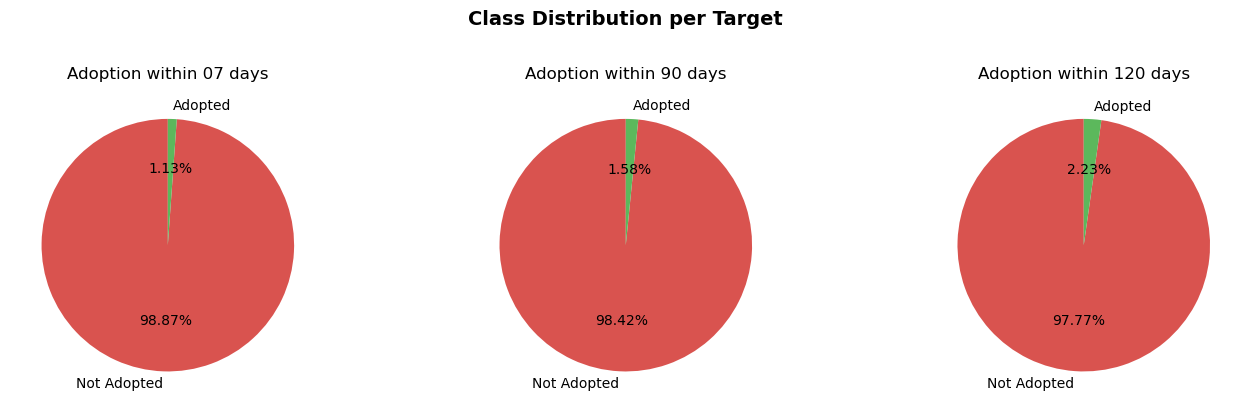

In [7]:
# Target class imbalance analysis
TARGETS = ['adopted_within_07_days', 'adopted_within_90_days', 'adopted_within_120_days']

print("=== Target Adoption Rates (class imbalance) ===")
for t in TARGETS:
    rate = train[t].mean()
    n_pos = train[t].sum()
    print(f"  {t[-8:]}: {rate:.3%} positive ({int(n_pos)} / {len(train)})")

# Target Distribution
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
targets_labels = ['07 days', '90 days', '120 days']

for ax, target, label in zip(axes, TARGETS, targets_labels):
    counts = train[target].value_counts()
    ax.pie(counts, labels=['Not Adopted', 'Adopted'], autopct='%1.2f%%',
           colors=['#d9534f', '#5cb85c'], startangle=90)
    ax.set_title(f'Adoption within {label}', fontsize=12)

plt.suptitle('Class Distribution per Target', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# Distribution of key categorical features
for col in ['gender', 'age', 'registration', 'belong_to_cooperative']:
    print(f"\n--- {col} ---")
    print(train[col].value_counts(dropna=False))


--- gender ---
gender
Female    9541
Male      3995
Name: count, dtype: int64

--- age ---
age
Above 35    10828
Below 35     2708
Name: count, dtype: int64

--- registration ---
registration
Ussd      8383
Manual    5153
Name: count, dtype: int64

--- belong_to_cooperative ---
belong_to_cooperative
0    11608
1     1928
Name: count, dtype: int64


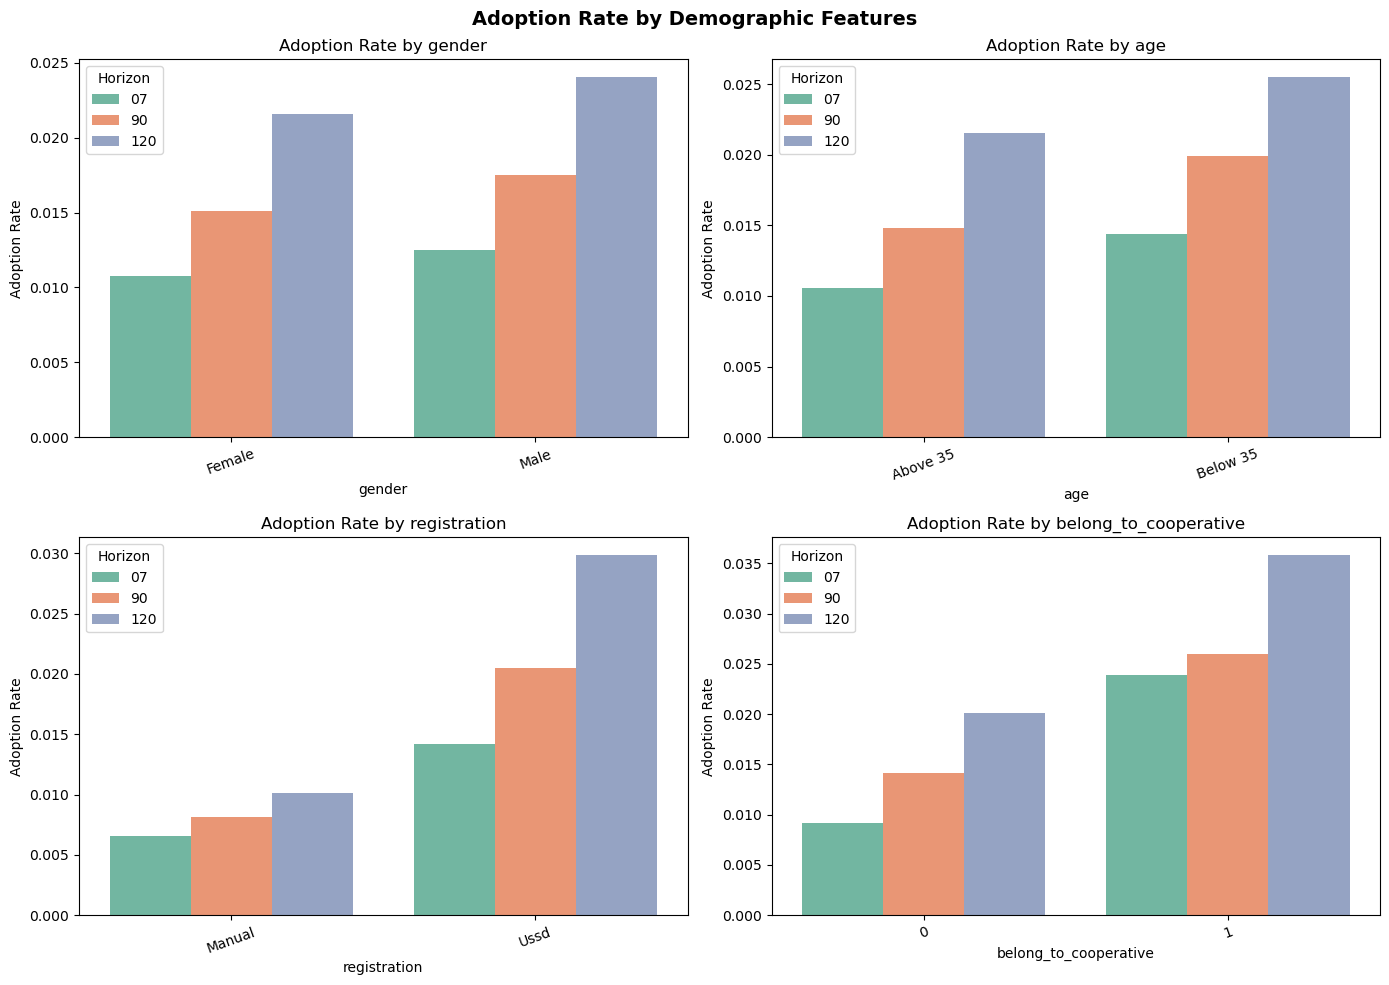

In [9]:
# Adoption Rate by Demographic Features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
cat_features = ['gender', 'age', 'registration', 'belong_to_cooperative']

for ax, col in zip(axes.flatten(), cat_features):
    data = train.groupby(col)[TARGETS].mean().reset_index()
    data_melted = data.melt(id_vars=col, value_vars=TARGETS,
                            var_name='Target', value_name='Adoption Rate')
    data_melted['Target'] = data_melted['Target'].str.extract(r'(\d+)_days')
    sns.barplot(data=data_melted, x=col, y='Adoption Rate', hue='Target', ax=ax, palette='Set2')
    ax.set_title(f'Adoption Rate by {col}', fontsize=12)
    ax.set_ylabel('Adoption Rate')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(title='Horizon')

plt.suptitle('Adoption Rate by Demographic Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Unique counties   : 8
Unique subcounties: 26
Unique wards      : 66
Unique groups     : 864
Unique farmers    : 13536

Top 10 counties by count:
county
CNT_vvuukv    3049
CNT_yljqnl    2190
CNT_mggvna    2168
CNT_lpotuu    2028
CNT_fhdsoy    1887
CNT_rihpna    1450
CNT_mvqqmw     734
CNT_hfhimd      30
Name: count, dtype: int64


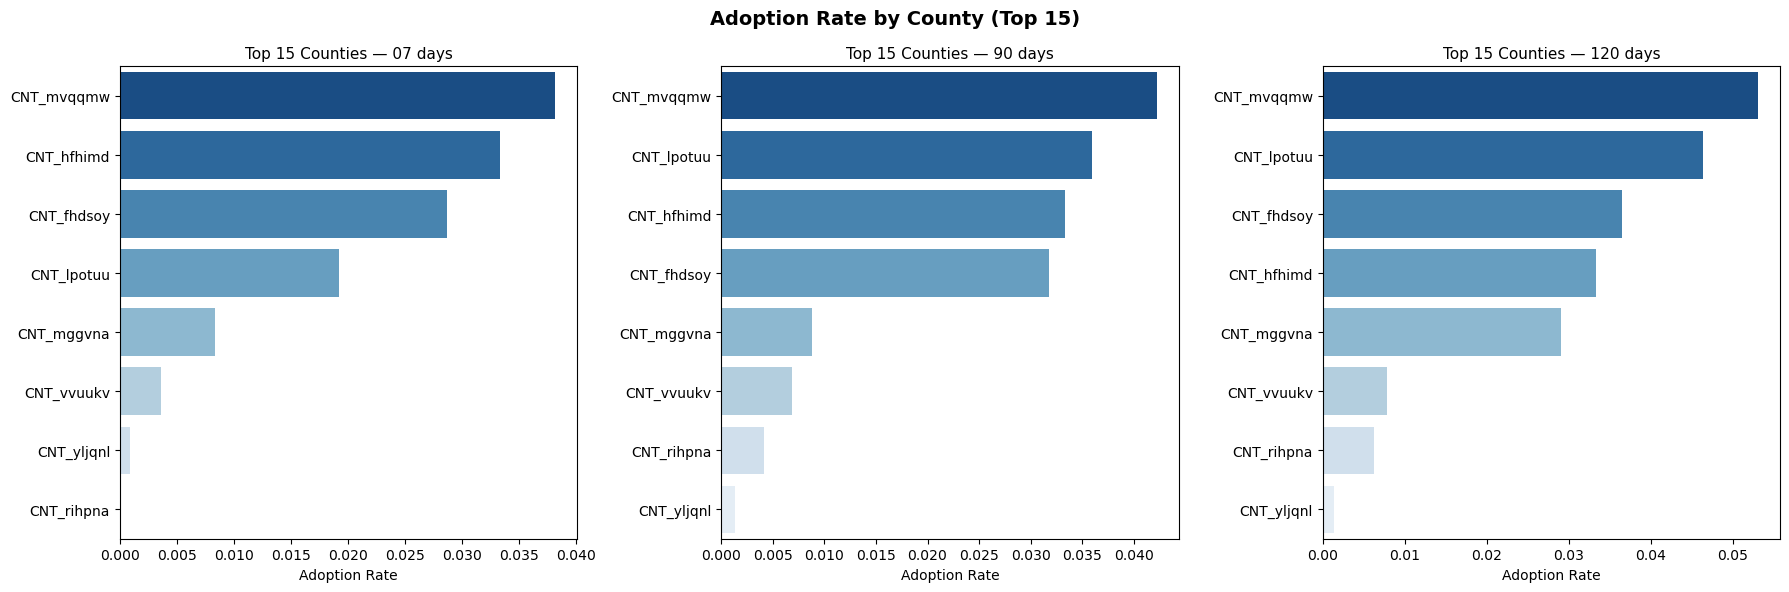

In [10]:
# Geographic distribution
print(f"Unique counties   : {train['county'].nunique()}")
print(f"Unique subcounties: {train['subcounty'].nunique()}")
print(f"Unique wards      : {train['ward'].nunique()}")
print(f"Unique groups     : {train['group_name'].nunique()}")
print(f"Unique farmers    : {train['farmer_name'].nunique()}")

print("\nTop 10 counties by count:")
print(train['county'].value_counts().head(10))

# Adoption Rate by County (Top 15)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (short, target) in zip(axes, SHORT_MAP):
    county_rate = (train.groupby('county')[target].mean()
                        .sort_values(ascending=False).head(15))
    sns.barplot(x=county_rate.values, y=county_rate.index, ax=ax,
                palette='Blues_r', orient='h')
    ax.set_title(f'Top 15 Counties — {short} days', fontsize=11)
    ax.set_xlabel('Adoption Rate')
    ax.set_ylabel('')

plt.suptitle('Adoption Rate by County (Top 15)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# Adoption rate by county (top 15)
county_stats = train.groupby('county')[TARGETS].mean().round(3)
county_stats['n'] = train.groupby('county').size()
county_stats.sort_values('adopted_within_90_days', ascending=False).head(15)

,adopted_within_07_days,adopted_within_90_days,adopted_within_120_days,n
county,,,,
CNT_mvqqmw,0.038,0.042,0.053,734
CNT_lpotuu,0.019,0.036,0.046,2028
CNT_hfhimd,0.033,0.033,0.033,30
CNT_fhdsoy,0.029,0.032,0.037,1887
CNT_mggvna,0.008,0.009,0.029,2168
CNT_vvuukv,0.004,0.007,0.008,3049
CNT_rihpna,0.000,0.004,0.006,1450
CNT_yljqnl,0.001,0.001,0.001,2190


In [12]:
# Adoption rate by gender and cooperative membership
print("Adoption rate by gender:")
print(train.groupby('gender')[TARGETS].mean().round(4))

print("\nAdoption rate by cooperative membership:")
print(train.groupby('belong_to_cooperative')[TARGETS].mean().round(4))

print("\nAdoption rate by age group:")
print(train.groupby('age')[TARGETS].mean().round(4))

print("\nAdoption rate by registration method:")
print(train.groupby('registration')[TARGETS].mean().round(4))

Adoption rate by gender:
        adopted_within_07_days  adopted_within_90_days  \
gender                                                   
Female                  0.0108                  0.0151   
Male                    0.0125                  0.0175   

        adopted_within_120_days  
gender                           
Female                   0.0216  
Male                     0.0240  

Adoption rate by cooperative membership:
                       adopted_within_07_days  adopted_within_90_days  \
belong_to_cooperative                                                   
0                                      0.0092                  0.0141   
1                                      0.0239                  0.0259   

                       adopted_within_120_days  
belong_to_cooperative                           
0                                       0.0201  
1                                       0.0358  

Adoption rate by age group:
          adopted_within_07_days  adopted_with

In [13]:
# Temporal EDA — training day distribution
train['training_day'] = pd.to_datetime(train['training_day'])
print(f"Training date range: {train['training_day'].min()} → {train['training_day'].max()}")

monthly = train.set_index('training_day').resample('M')[TARGETS].mean().round(4)
print("\nMonthly adoption rates (sample):")
print(monthly.tail(10))

Training date range: 2024-01-03 00:00:00 → 2025-04-12 00:00:00

Monthly adoption rates (sample):
              adopted_within_07_days  adopted_within_90_days  \
training_day                                                   
2024-07-31                    0.0011                  0.0076   
2024-08-31                    0.0101                  0.0152   
2024-09-30                    0.0198                  0.0209   
2024-10-31                    0.0091                  0.0124   
2024-11-30                    0.0207                  0.0238   
2024-12-31                    0.0137                  0.0216   
2025-01-31                    0.0194                  0.0194   
2025-02-28                    0.0162                  0.0162   
2025-03-31                    0.0172                  0.0172   
2025-04-30                    0.0098                  0.0098   

              adopted_within_120_days  
training_day                           
2024-07-31                     0.0207  
2024-08-31    

## 2. Helper Functions — Parsing

In [15]:
def parse_topics(s):
    try:
        raw = ast.literal_eval(str(s))
        out = []
        for item in raw:
            if isinstance(item, list): out.extend([t for t in item if isinstance(t,str)])
            elif isinstance(item,str): out.append(item)
        return [t.strip().lower() for t in out if t.strip()]
    except: return []

def parse_trainers(s):
    """Parse a stringified list of trainer IDs into a list of strings."""
    try:
        raw = ast.literal_eval(str(s))
        return [str(t) for t in raw] if isinstance(raw,list) else [str(raw)]
    except: return [str(s)]

def topic_entropy(topics):
    """Shannon entropy of topic frequencies — measures topic diversity."""
    if not topics:
        return 0.0
    _, counts = np.unique(topics, return_counts=True)
    probs = counts / counts.sum()
    return float(scipy_entropy(probs))

# Quick sanity check on parsers
sample_topics = train['topics_list'].iloc[0]
print(f"Raw : {sample_topics}")
print(f"Parsed: {parse_topics(sample_topics)}")

Raw : [['Ndume App', 'Poultry Feeding']]
Parsed: ['ndume app', 'poultry feeding']


Text(0, 0.5, 'Adoption Rate')

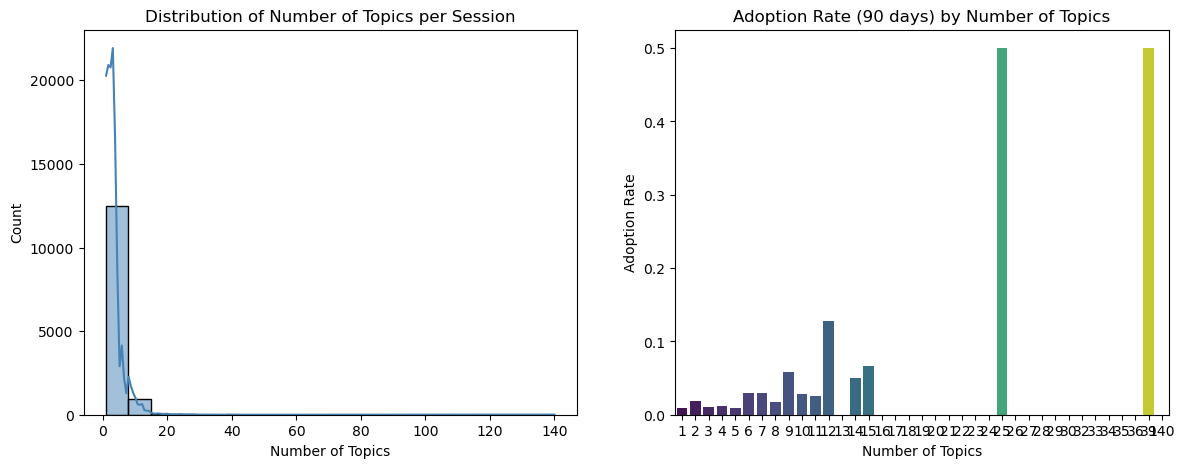

In [16]:
train['n_topics'] = train['topics_list'].apply(lambda x: len(parse_topics(x)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution globale
sns.histplot(train['n_topics'], bins=20, ax=axes[0], color='steelblue', kde=True)
axes[0].set_title('Distribution of Number of Topics per Session', fontsize=12)
axes[0].set_xlabel('Number of Topics')

# n_topics vs adoption rate (90 days)
topic_adoption = train.groupby('n_topics')['adopted_within_90_days'].mean().reset_index()
sns.barplot(data=topic_adoption, x='n_topics', y='adopted_within_90_days',
            ax=axes[1], palette='viridis')
axes[1].set_title('Adoption Rate (90 days) by Number of Topics', fontsize=12)
axes[1].set_xlabel('Number of Topics')
axes[1].set_ylabel('Adoption Rate')

## 3. Prior Statistics (Smoothed Target Encoding from Historical Data)

In [17]:
def build_prior_stats(prior):
    print("  Computing prior statistics...")
    p = prior.copy()
    p['training_day'] = pd.to_datetime(p['training_day'])
    p['month']        = p['training_day'].dt.month
    p['dayofweek']    = p['training_day'].dt.dayofweek
    p['quarter']      = p['training_day'].dt.quarter
    p['week']         = p['training_day'].dt.isocalendar().week.astype(int)
    p['year_month']   = p['training_day'].dt.to_period('M').astype(str)
    p['topics_parsed']= p['topics_list'].apply(parse_topics)
    p['trainer_first']= p['trainer'].apply(
        lambda x: parse_trainers(x)[0] if parse_trainers(x) else 'unknown')

    TARGETS = ['adopted_within_07_days','adopted_within_90_days','adopted_within_120_days']
    stats = {}
    global_rates = {t: p[t].mean() for t in TARGETS}
    stats['global_rates'] = global_rates

    SMOOTH_K = 50  # smoothing strength — higher = more shrinkage toward global mean
    cat_cols = ['county','subcounty','ward','group_name','trainer_first',
                'gender','age','registration','month','dayofweek','quarter',
                'belong_to_cooperative','has_topic_trained_on','year_month','week']
    for col in cat_cols:
        if col not in p.columns: continue
        for target in TARGETS:
            gr  = global_rates[target]
            agg = p.groupby(col)[target].agg(['sum','count'])
            agg['rate'] = (agg['sum'] + SMOOTH_K * gr) / (agg['count'] + SMOOTH_K)
            agg['var']  = agg['rate'] * (1-agg['rate']) / (agg['count']+1)
            stats[f'{col}_{target}_rate'] = agg['rate'].to_dict()
            stats[f'{col}_{target}_var']  = agg['var'].to_dict()
            stats[f'{col}_{target}_cnt']  = agg['count'].to_dict()

    # Trainer quality score: smoothed adoption rate per trainer
    for target in TARGETS:
        gr  = global_rates[target]
        agg = p.groupby('trainer_first')[target].agg(['sum','count'])
        agg['quality'] = (agg['sum'] + 30*gr) / (agg['count'] + 30)
        agg['consistency'] = agg['quality'] * (1-agg['quality']) / (agg['count']+1)
        stats[f'trainer_quality_{target}'] = agg['quality'].to_dict()
        stats[f'trainer_consistency_{target}'] = agg['consistency'].to_dict()

    # Farmer history: number of past sessions and historical adoption rate per farmer
    farmer_stats = {}
    for farmer, grp in p.groupby('farmer_name'):
        farmer_stats[farmer] = {
            'count': len(grp),
            'last_date': grp['training_day'].max(),
        }
        for target in TARGETS:
            farmer_stats[farmer][f'{target}_rate'] = grp[target].mean()
    stats['farmer_history'] = farmer_stats

    # Group cohesion: 1 − std of adoption outcomes within a group (1 = very consistent)
    for target in TARGETS:
        gr = global_rates[target]
        agg = p.groupby('group_name')[target].agg(['mean','std','count'])
        agg['cohesion'] = 1 - agg['std'].fillna(0)
        agg['rate'] = (agg['mean'] * agg['count'] + SMOOTH_K*gr) / (agg['count'] + SMOOTH_K)
        stats[f'group_cohesion_{target}'] = agg['cohesion'].to_dict()

    # Topic-level smoothed adoption rates
    rows = []
    for _, row in p.iterrows():
        for topic in row['topics_parsed']:
            rows.append({'topic': topic,
                         'adopted_within_07_days':  row['adopted_within_07_days'],
                         'adopted_within_90_days':  row['adopted_within_90_days'],
                         'adopted_within_120_days': row['adopted_within_120_days']})
    if rows:
        tdf = pd.DataFrame(rows)
        for target in TARGETS:
            gr  = global_rates[target]
            agg = tdf.groupby('topic')[target].agg(['sum','count'])
            agg['rate'] = (agg['sum'] + 30*gr) / (agg['count']+30)
            stats[f'topic_{target}_rate']  = agg['rate'].to_dict()
            stats[f'topic_{target}_count'] = agg['count'].to_dict()

    # County × year-month interaction rates
    for target in TARGETS:
        gr  = global_rates[target]
        agg = p.groupby(['county','year_month'])[target].agg(['sum','count'])
        agg['rate'] = (agg['sum'] + 20*gr) / (agg['count']+20)
        stats[f'county_ym_{target}_rate'] = agg['rate'].to_dict()

    # County × week interaction rates
    for target in TARGETS:
        gr = global_rates[target]
        agg = p.groupby(['county','week'])[target].agg(['sum','count'])
        agg['rate'] = (agg['sum'] + 15*gr) / (agg['count']+15)
        stats[f'county_week_{target}_rate'] = agg['rate'].to_dict()

    # Count statistics for frequency-based features
    stats['farmer_prior_count']    = p['farmer_name'].value_counts().to_dict()
    stats['group_size']            = p['group_name'].value_counts().to_dict()
    stats['trainer_event_count']   = p['trainer_first'].value_counts().to_dict()
    stats['county_event_count']    = p['county'].value_counts().to_dict()
    stats['ward_event_count']      = p['ward'].value_counts().to_dict()
    stats['subcounty_event_count'] = p['subcounty'].value_counts().to_dict()

    # Pairwise interaction rates between geographic and demographic columns
    SMOOTH_K2 = 20
    interactions = [('county','gender'),('county','age'),('ward','belong_to_cooperative'),
                    ('group_name','gender'),('county','registration'),
                    ('county','has_topic_trained_on'),('subcounty','gender'),
                    ('county','month'),('ward','gender'),('subcounty','age'),
                    ('trainer_first','gender'),('group_name','belong_to_cooperative')]
    for (c1,c2) in interactions:
        if c1 not in p.columns or c2 not in p.columns: continue
        key = f'{c1}_{c2}'
        p[key] = p[c1].astype(str)+'_'+p[c2].astype(str)
        for target in TARGETS:
            gr  = global_rates[target]
            agg = p.groupby(key)[target].agg(['sum','count'])
            agg['rate'] = (agg['sum'] + SMOOTH_K2*gr) / (agg['count']+SMOOTH_K2)
            stats[f'{key}_{target}_rate'] = agg['rate'].to_dict()

    county_first_date = p.groupby('county')['training_day'].min()
    stats['county_first_date'] = county_first_date.to_dict()
    stats['overall_date_range'] = (p['training_day'].min(), p['training_day'].max())
    return stats


prior_stats = build_prior_stats(prior)
print(f"\nGlobal adoption rates (from Prior):")
for k, v in prior_stats['global_rates'].items():
    print(f"  {k[-8:]}: {v:.3%}")

  Computing prior statistics...

Global adoption rates (from Prior):
  _07_days: 1.479%
  _90_days: 3.404%
  120_days: 4.650%


## 4. Feature Engineering

In [18]:
def oof_target_encode(train_df, col, target, n_splits=5, smooth_k=50):
    global_rate = train_df[target].mean()
    encoded = np.full(len(train_df), global_rate, dtype=np.float32)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    for tr_idx, val_idx in skf.split(train_df, train_df[target]):
        tr_sub  = train_df.iloc[tr_idx]
        val_sub = train_df.iloc[val_idx]
        agg = tr_sub.groupby(col)[target].agg(['sum','count'])
        agg['rate'] = (agg['sum'] + smooth_k*global_rate) / (agg['count']+smooth_k)
        encoded[val_idx] = val_sub[col].map(agg['rate'].to_dict()).fillna(global_rate).values
    return encoded


def to_float32(arr):
    """Convert array to float32 contiguous memory for ML libraries."""
    return np.ascontiguousarray(arr, dtype=np.float32)


def feature_engineer(df, prior_stats, train_df=None, is_train=True):
    """
    Full feature engineering pipeline.
    Creates ~294 features across these groups:
      - Temporal (cyclic sin/cos encoding, time position, weekend flags)
      - Demographic (age, gender, registration encodings)
      - Topic features (counts, entropy, category flags, smoothed rates)
      - Trainer features (quality score, consistency, event count)
      - Geography features (county/ward/subcounty smoothed rates, OOF encoding)
      - Farmer history (prior session count, recency, historical adoption rate)
      - Group features (size, cohesion score)
      - Cross-feature interactions and composite scores
      - Cross-target ratios (07/90, 07/120, 90/120)
    """
    df = df.copy()
    gr = prior_stats['global_rates']
    overall_min, overall_max = prior_stats['overall_date_range']
    date_range_days = max((overall_max - overall_min).days, 1)

    # --- Temporal features ---
    df['training_day']  = pd.to_datetime(df['training_day'])
    df['month']         = df['training_day'].dt.month
    df['dayofweek']     = df['training_day'].dt.dayofweek
    df['week']          = df['training_day'].dt.isocalendar().week.astype(int)
    df['quarter']       = df['training_day'].dt.quarter
    df['is_weekend']    = (df['dayofweek'] >= 5).astype(int)
    df['day_of_month']  = df['training_day'].dt.day
    df['is_month_end']  = (df['day_of_month'] >= 25).astype(int)
    df['is_month_start']= (df['day_of_month'] <= 5).astype(int)
    df['year_month']    = df['training_day'].dt.to_period('M').astype(str)
    # Normalized position in the overall date range [0, 1]
    df['time_position'] = ((df['training_day']-overall_min).dt.days / date_range_days).clip(0,1)
    # Cyclic encoding to preserve calendar periodicity
    df['month_sin']     = np.sin(2*np.pi*df['month']/12)
    df['month_cos']     = np.cos(2*np.pi*df['month']/12)
    df['dow_sin']       = np.sin(2*np.pi*df['dayofweek']/7)
    df['dow_cos']       = np.cos(2*np.pi*df['dayofweek']/7)
    df['week_sin']      = np.sin(2*np.pi*df['week']/52)
    df['week_cos']      = np.cos(2*np.pi*df['week']/52)

    # --- Demographic features ---
    age_map = {'Below 18':0,'18-25':1,'26-35':2,'Above 35':3}
    df['age_enc']         = df['age'].map(age_map).fillna(2).astype(int)
    df['gender_enc']      = (df['gender']=='Female').astype(int)
    reg_map = {'Ussd':1,'Manual':0,'App':2}
    df['registration_enc']= df['registration'].map(reg_map).fillna(0).astype(int)

    # --- Topic features ---
    df['topics_parsed']   = df['topics_list'].apply(parse_topics)
    df['n_topics']        = df['topics_parsed'].apply(len)
    df['n_unique_topics'] = df['topics_parsed'].apply(lambda x: len(set(x)))
    df['topics_ratio']    = df['n_unique_topics'] / (df['n_topics']+1)
    # Topic diversity measured via Shannon entropy
    df['topic_entropy']   = df['topics_parsed'].apply(topic_entropy)

    # Count topics per category and create binary flags
    for cat, kws in TOPIC_KEYWORDS.items():
        df[f'n_{cat}_topics'] = df['topics_parsed'].apply(
            lambda ts: sum(any(kw in t for kw in kws) for t in ts))
    df['n_category_types'] = sum(
        (df[f'n_{cat}_topics']>0).astype(int) for cat in TOPIC_KEYWORDS)
    df['has_digital_topic']= (df['n_digital_topics']>0).astype(int)
    df['has_dairy_topic']  = (df['n_dairy_topics']>0).astype(int)
    df['has_health_topic'] = (df['n_health_topics']>0).astype(int)
    df['has_poultry_topic']= (df['n_poultry_topics']>0).astype(int)
    df['has_finance_topic']= (df['n_finance_topics']>0).astype(int)

    # Topic-level adoption rate statistics
    for short, target in SHORT_MAP:
        rd = prior_stats.get(f'topic_{target}_rate',{})
        cd = prior_stats.get(f'topic_{target}_count',{})
        default = gr[target]
        df[f'topic_avg_{short}_rate'] = df['topics_parsed'].apply(
            lambda ts: np.mean([rd.get(t,default) for t in ts]) if ts else default)
        df[f'topic_max_{short}_rate'] = df['topics_parsed'].apply(
            lambda ts: np.max([rd.get(t,default) for t in ts]) if ts else default)
        df[f'topic_min_{short}_rate'] = df['topics_parsed'].apply(
            lambda ts: np.min([rd.get(t,default) for t in ts]) if ts else default)
        df[f'topic_std_{short}_rate'] = df['topics_parsed'].apply(
            lambda ts: np.std([rd.get(t,default) for t in ts]) if len(ts)>1 else 0)
        df[f'topic_sum_{short}_count']= df['topics_parsed'].apply(
            lambda ts: sum(cd.get(t,0) for t in ts))

    # --- Trainer features ---
    df['trainers_parsed']     = df['trainer'].apply(parse_trainers)
    df['n_trainers']          = df['trainers_parsed'].apply(len)
    df['trainer_first']       = df['trainers_parsed'].apply(lambda x: x[0] if x else 'unknown')
    df['trainer_event_count'] = df['trainer_first'].map(
        prior_stats.get('trainer_event_count',{})).fillna(1)
    df['trainer_event_log']   = np.log1p(df['trainer_event_count'])

    # Trainer quality: smoothed historical adoption rate of this trainer
    for short, target in SHORT_MAP:
        tq = prior_stats.get(f'trainer_quality_{target}', {})
        tc = prior_stats.get(f'trainer_consistency_{target}', {})
        df[f'trainer_quality_{short}'] = df['trainer_first'].map(tq).fillna(gr[target])
        df[f'trainer_consistency_{short}'] = df['trainer_first'].map(tc).fillna(0)

    # --- Geographic smoothed rates from Prior ---
    cat_cols = [
        ('county','county'),('subcounty','subcounty'),('ward','ward'),
        ('group_name','group_name'),('trainer_first','trainer_first'),
        ('gender','gender'),('age','age'),('registration','registration'),
        ('month','month'),('dayofweek','dayofweek'),('quarter','quarter'),
        ('belong_to_cooperative','belong_to_cooperative'),
        ('has_topic_trained_on','has_topic_trained_on'),('year_month','year_month'),
        ('week','week'),
    ]
    for col, key in cat_cols:
        if col not in df.columns: continue
        for short, target in SHORT_MAP:
            rd  = prior_stats.get(f'{key}_{target}_rate',{})
            vd  = prior_stats.get(f'{key}_{target}_var',{})
            default = gr[target]
            df[f'{key}_{short}_rate'] = df[col].map(rd).fillna(default)
            df[f'{key}_{short}_var']  = df[col].map(vd).fillna(0)

    # OOF target encoding for key geographic columns (avoids leakage on train)
    if train_df is not None:
        for col in ['county','ward','group_name','trainer_first','subcounty']:
            if col not in train_df.columns: continue
            for short, target in SHORT_MAP:
                fname = f'{col}_oof_{short}_rate'
                if is_train:
                    df[fname] = oof_target_encode(train_df, col, target)
                else:
                    global_rate = train_df[target].mean()
                    agg = train_df.groupby(col)[target].agg(['sum','count'])
                    agg['rate'] = (agg['sum']+50*global_rate)/(agg['count']+50)
                    df[fname] = df[col].map(agg['rate'].to_dict()).fillna(global_rate)

    # Pairwise interaction rates
    interactions = [('county','gender'),('county','age'),('ward','belong_to_cooperative'),
                    ('group_name','gender'),('county','registration'),
                    ('county','has_topic_trained_on'),('subcounty','gender'),
                    ('county','month'),('ward','gender'),('subcounty','age'),
                    ('trainer_first','gender'),('group_name','belong_to_cooperative')]
    for (c1,c2) in interactions:
        if c1 not in df.columns or c2 not in df.columns: continue
        key = f'{c1}_{c2}'
        df[key] = df[c1].astype(str)+'_'+df[c2].astype(str)
        for short, target in SHORT_MAP:
            rd = prior_stats.get(f'{key}_{target}_rate',{})
            df[f'{key}_{short}_rate'] = df[key].map(rd).fillna(gr[target])
        df.drop(columns=[key], inplace=True)

    # County × time interaction rates
    for short, target in SHORT_MAP:
        rd = prior_stats.get(f'county_ym_{target}_rate',{})
        default = gr[target]
        df[f'county_ym_{short}_rate'] = df.apply(
            lambda r: rd.get((r['county'],r['year_month']),default), axis=1)
        df[f'county_trend_{short}'] = df[f'county_ym_{short}_rate'] - df[f'county_{short}_rate']
        rw = prior_stats.get(f'county_week_{target}_rate', {})
        df[f'county_week_{short}_rate'] = df.apply(
            lambda r: rw.get((r['county'], r['week']), default), axis=1)

    # --- Farmer history features ---
    farmer_history = prior_stats.get('farmer_history', {})
    df['farmer_prior_count_raw'] = df['farmer_name'].map(
        lambda x: farmer_history.get(x, {}).get('count', 0))
    df['farmer_prior_count']     = df['farmer_prior_count_raw']
    df['farmer_experienced']     = (df['farmer_prior_count'] > 1).astype(int)
    df['farmer_prior_log']       = np.log1p(df['farmer_prior_count'])
    for short, target in SHORT_MAP:
        key = f'{target}_rate'
        df[f'farmer_hist_{short}_rate'] = df['farmer_name'].map(
            lambda x: farmer_history.get(x, {}).get(key, gr[target]))

    # Recency: days since last prior training session
    ref_date = overall_max
    df['farmer_recency_days'] = df['farmer_name'].map(
        lambda x: (ref_date - farmer_history[x]['last_date']).days
        if x in farmer_history else 999)
    df['farmer_recency_log'] = np.log1p(df['farmer_recency_days'])

    # --- Group features ---
    for short, target in SHORT_MAP:
        gc = prior_stats.get(f'group_cohesion_{target}', {})
        df[f'group_cohesion_{short}'] = df['group_name'].map(gc).fillna(0.5)

    df['group_size']           = df['group_name'].map(
        prior_stats.get('group_size',{})).fillna(1)
    df['group_size_log']       = np.log1p(df['group_size'])
    df['county_event_count']   = df['county'].map(
        prior_stats.get('county_event_count',{})).fillna(1)
    df['ward_event_count']     = df['ward'].map(
        prior_stats.get('ward_event_count',{})).fillna(1)
    df['ward_event_log']       = np.log1p(df['ward_event_count'])

    # Percentile ranks for rate features
    for short in ['07','90','120']:
        if f'county_{short}_rate' in df.columns:
            df[f'county_{short}_percentile'] = pd.Series(
                df[f'county_{short}_rate'].values).rank(pct=True).values
        if f'ward_{short}_rate' in df.columns:
            df[f'ward_{short}_percentile'] = pd.Series(
                df[f'ward_{short}_rate'].values).rank(pct=True).values
        if f'topic_avg_{short}_rate' in df.columns:
            df[f'topic_{short}_percentile'] = pd.Series(
                df[f'topic_avg_{short}_rate'].values).rank(pct=True).values

    # Composite weighted score and interaction terms per target horizon
    for short in ['07','90','120']:
        df[f'composite_{short}'] = (
            0.20*df[f'county_{short}_rate'] +
            0.20*df[f'topic_avg_{short}_rate'] +
            0.15*df[f'ward_{short}_rate'] +
            0.15*df[f'group_name_{short}_rate'] +
            0.15*df[f'trainer_first_{short}_rate'] +
            0.15*df[f'trainer_quality_{short}'])
        df[f'coop_county_{short}']    = df['belong_to_cooperative']*df[f'county_{short}_rate']
        df[f'gender_county_{short}']  = df['gender_enc']*df[f'county_{short}_rate']
        df[f'topic_county_{short}']   = df[f'topic_avg_{short}_rate']*df[f'county_{short}_rate']
        df[f'trainer_county_{short}'] = df[f'trainer_first_{short}_rate']*df[f'county_{short}_rate']
        df[f'age_county_{short}']     = df['age_enc']*df[f'county_{short}_rate']
        df[f'topic_vs_county_{short}']= df[f'topic_avg_{short}_rate']/(df[f'county_{short}_rate']+1e-6)
        df[f'ward_coop_{short}']      = df[f'ward_{short}_rate']*df['belong_to_cooperative']
        df[f'county_vs_global_{short}']= df[f'county_{short}_rate'] - gr[SHORT_TO_TARGET[short]]
        df[f'topic_vs_global_{short}'] = df[f'topic_avg_{short}_rate'] - gr[SHORT_TO_TARGET[short]]
        if f'county_{short}_percentile' in df.columns:
            df[f'percentile_coop_{short}'] = df[f'county_{short}_percentile']*df['belong_to_cooperative']
        # Farmer vs. county signal (deviation from local baseline)
        df[f'farmer_vs_county_{short}'] = (
            df[f'farmer_hist_{short}_rate'] - df[f'county_{short}_rate'])
        df[f'farmer_trainer_{short}'] = (
            df[f'farmer_hist_{short}_rate'] * df[f'trainer_quality_{short}'])

    # Cross-target ratios to capture relative adoption speed
    if 'composite_07' in df.columns and 'composite_90' in df.columns:
        df['ratio_07_90']  = df['composite_07'] / (df['composite_90'] + 1e-6)
        df['ratio_07_120'] = df['composite_07'] / (df['topic_avg_120_rate'] + 1e-6)
        df['ratio_90_120'] = df['composite_90'] / (df['topic_avg_120_rate'] + 1e-6)

    # Additional interaction terms
    df['topics_coop']      = df['n_topics']*df['belong_to_cooperative']
    df['age_coop']         = df['age_enc']*df['belong_to_cooperative']
    df['experienced_coop'] = df['farmer_experienced']*df['belong_to_cooperative']
    df['digital_coop']     = df['has_digital_topic']*df['belong_to_cooperative']
    df['n_topics_x_reg']   = df['n_topics']*df['registration_enc']
    df['age_x_reg']        = df['age_enc']*df['registration_enc']
    df['time_x_coop']      = df['time_position']*df['belong_to_cooperative']
    df['age_x_digital']    = df['age_enc']*df['has_digital_topic']
    df['gender_x_coop']    = df['gender_enc']*df['belong_to_cooperative']
    df['entropy_x_coop']   = df['topic_entropy']*df['belong_to_cooperative']
    df['farmer_log_x_coop']= df['farmer_prior_log']*df['belong_to_cooperative']

    # Label encoding for tree models
    for col in ['county','subcounty','ward','group_name','trainer_first']:
        le = LabelEncoder()
        df[f'{col}_le'] = le.fit_transform(df[col].fillna('unknown').astype(str))

    return df


def get_feature_cols(train_fe):
    """Return list of numeric feature columns, excluding IDs and target columns."""
    exclude = [
        'ID','farmer_name','training_day','gender','age','registration',
        'group_name','county','subcounty','ward','trainer','topics_list',
        'trainer_first','topics_parsed','trainers_parsed','year_month',
        'adopted_within_07_days','adopted_within_90_days','adopted_within_120_days',
    ]
    cols = [c for c in train_fe.columns
            if c not in exclude
            and train_fe[c].dtype in [np.float64,np.int64,np.float32,np.int32]
            and not train_fe[c].isnull().all()]
    return cols


# Run feature engineering
print("Running feature engineering on train...")
train_fe = feature_engineer(train, prior_stats, train_df=train, is_train=True)
print("Running feature engineering on test...")
test_fe  = feature_engineer(test,  prior_stats, train_df=train, is_train=False)
feature_cols = get_feature_cols(train_fe)
print(f"\nTotal features: {len(feature_cols)}")

Running feature engineering on train...
Running feature engineering on test...

Total features: 293


## 5. Feature Analysis — Importance & Correlation


Top 10 features correlated with adopted_within_07_days:
group_name_oof_07_rate                  0.283597
topic_county_07                         0.258691
group_name_oof_90_rate                  0.239425
county_has_topic_trained_on_120_rate    0.235537
topic_county_90                         0.234214
topic_avg_07_rate                       0.218719
topic_vs_global_07                      0.218719
topic_min_07_rate                       0.212147
topic_county_120                        0.208773
composite_07                            0.207702

Top 10 features correlated with adopted_within_90_days:
county_has_topic_trained_on_120_rate    0.272239
group_name_oof_07_rate                  0.271640
group_name_oof_90_rate                  0.250604
topic_county_07                         0.231994
topic_county_90                         0.224806
county_has_topic_trained_on_07_rate     0.211117
topic_max_90_rate                       0.208056
topic_county_120                        0.207434
coun

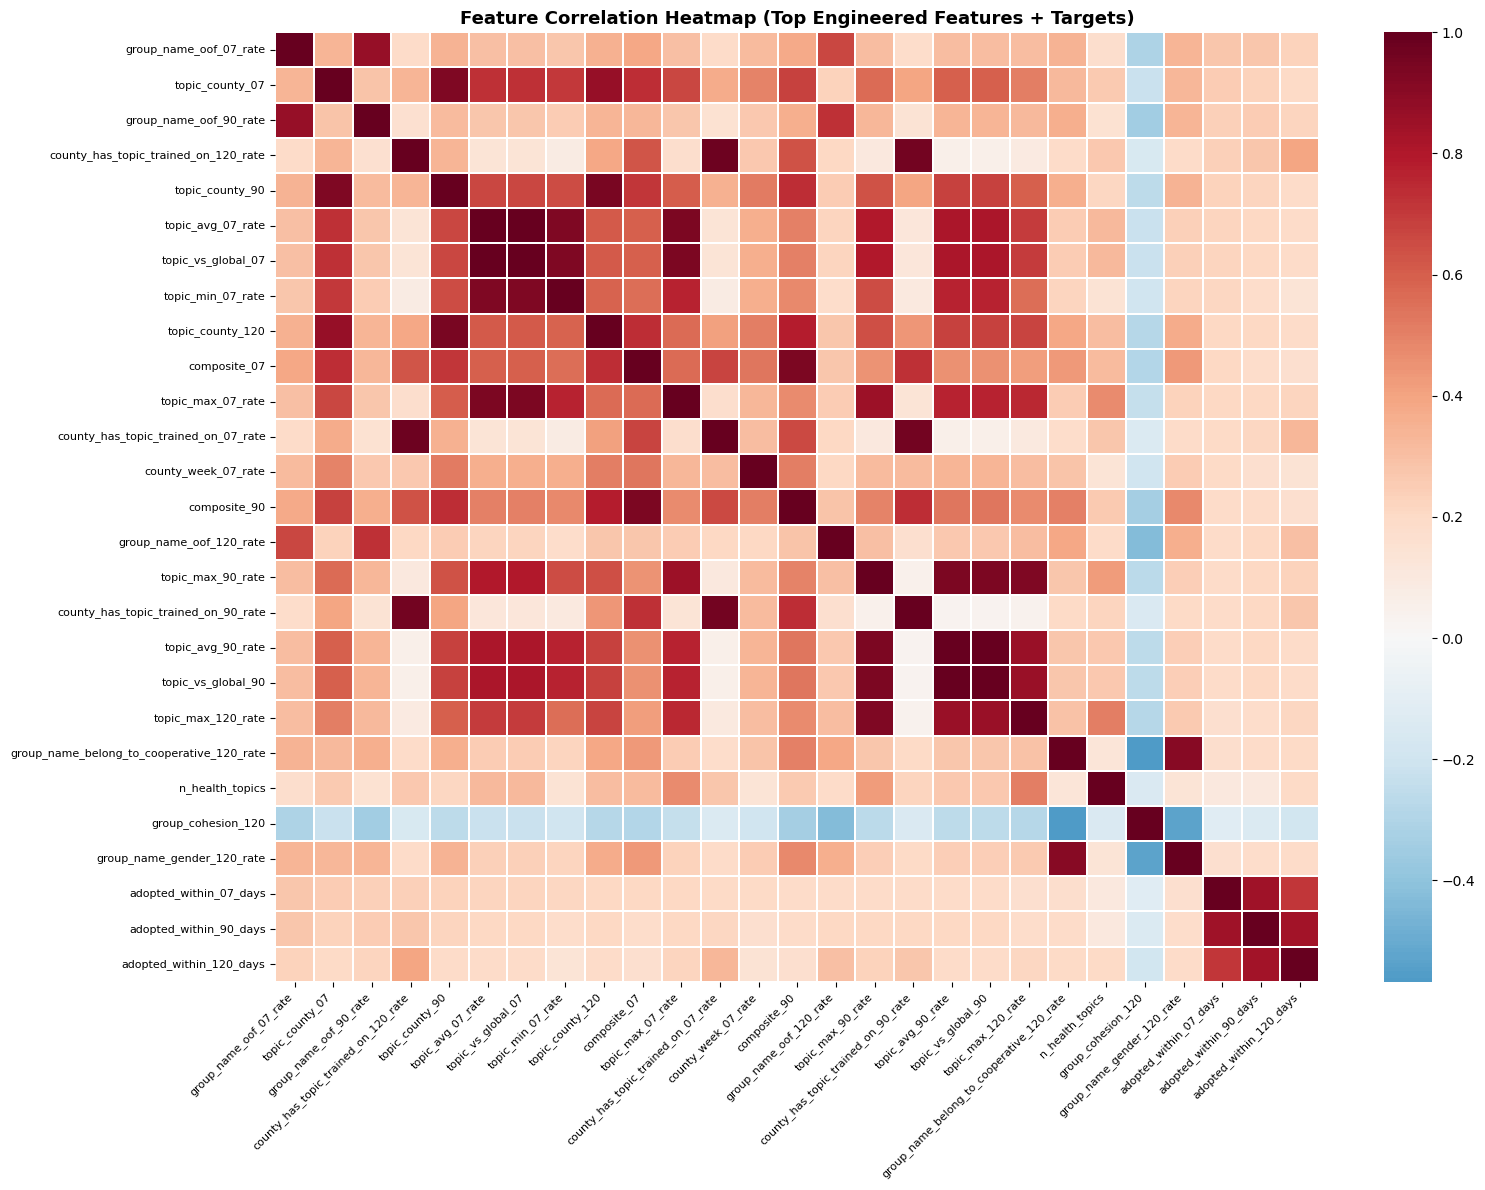

In [19]:
# Quick correlation of engineered features with each target
target_corrs = {}
for short, target in SHORT_MAP:
    corrs = train_fe[feature_cols].corrwith(train_fe[target]).abs().sort_values(ascending=False)
    target_corrs[short] = corrs
    print(f"\nTop 10 features correlated with {target}:")
    print(corrs.head(10).to_string())


# À placer après feature engineering (section 5 du notebook)
top_features_07  = target_corrs['07'].head(15).index.tolist()
top_features_90  = target_corrs['90'].head(15).index.tolist()
top_features_120 = target_corrs['120'].head(15).index.tolist()
top_all = list(dict.fromkeys(top_features_07 + top_features_90 + top_features_120))

corr_matrix = train_fe[top_all + TARGETS].corr()

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.zeros_like(corr_matrix, dtype=bool)
sns.heatmap(corr_matrix, ax=ax, cmap='RdBu_r', center=0,
            annot=False, linewidths=0.3, mask=mask,
            xticklabels=corr_matrix.columns, yticklabels=corr_matrix.columns)
ax.set_title('Feature Correlation Heatmap (Top Engineered Features + Targets)',
             fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

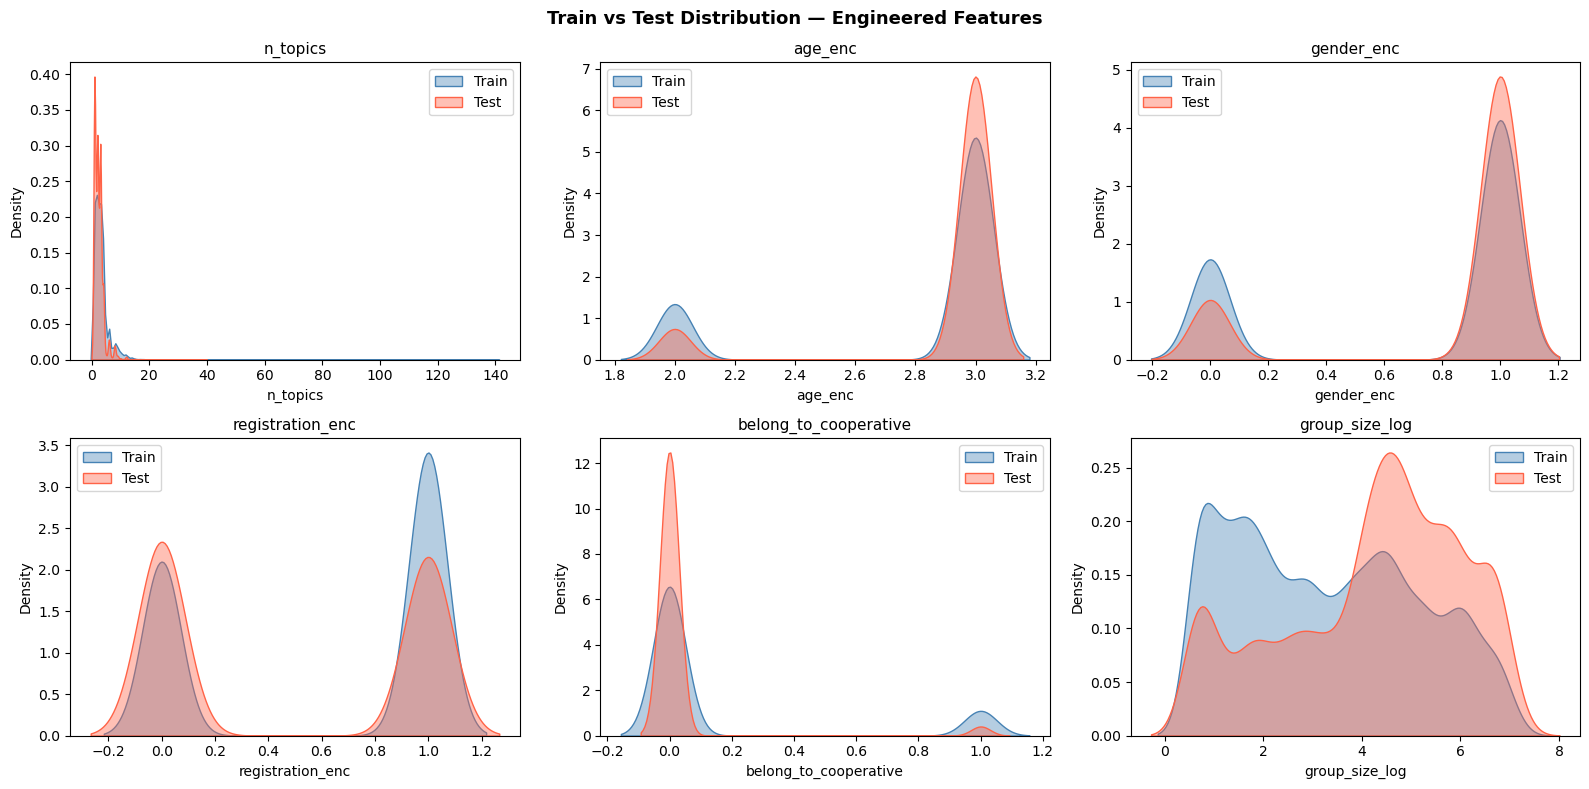

In [20]:
# Distribution train vs test in key features
compare_features = ['n_topics', 'age_enc', 'gender_enc', 'registration_enc',
                    'belong_to_cooperative', 'group_size_log']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, feat in zip(axes.flatten(), compare_features):
    if feat not in train_fe.columns or feat not in test_fe.columns:
        continue
    sns.kdeplot(train_fe[feat].dropna(), ax=ax, label='Train', fill=True, alpha=0.4, color='steelblue')
    sns.kdeplot(test_fe[feat].dropna(),  ax=ax, label='Test',  fill=True, alpha=0.4, color='tomato')
    ax.set_title(feat, fontsize=11)
    ax.legend()

plt.suptitle('Train vs Test Distribution — Engineered Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [21]:
# Feature variance — detect zero-variance features
var = train_fe[feature_cols].var()
zero_var = var[var == 0]
print(f"Zero-variance features: {len(zero_var)}")
if len(zero_var) > 0:
    print(zero_var.index.tolist())

# Missing value counts in engineered features
na_counts = train_fe[feature_cols].isnull().sum()
na_counts = na_counts[na_counts > 0]
print(f"\nFeatures with missing values: {len(na_counts)}")
if len(na_counts) > 0:
    print(na_counts.head(20))

Zero-variance features: 1
['is_month_end']

Features with missing values: 0


## 6. Hyperparameter Tuning with Optuna (Optional)

In [22]:
def tune_lgbm(X_tr, y_tr, X_val, y_val, scale_pos_weight, n_trials=N_OPTUNA_TRIALS):
    """Optuna TPE search for LightGBM hyperparameters, minimizing validation log-loss."""
    def objective(trial):
        params = {
            'n_estimators':      trial.suggest_int('n_estimators', 500, 4000),
            'learning_rate':     trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
            'num_leaves':        trial.suggest_int('num_leaves', 15, 127),
            'max_depth':         trial.suggest_int('max_depth', 3, 9),
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
            'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
            'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 5.0, log=True),
            'scale_pos_weight':  scale_pos_weight,
            'device':            GPU_DEVICE_LGBM,
            'random_state': 42, 'n_jobs': 1 if USE_GPU else -1, 'verbose': -1,
        }
        model = lgb.LGBMClassifier(**params)
        model.fit(X_tr, y_tr,
                  eval_set=[(X_val,y_val)],
                  callbacks=[lgb.early_stopping(50,verbose=False),
                              lgb.log_evaluation(-1)])
        return log_loss(y_val, model.predict_proba(X_val)[:,1])

    sampler = optuna.samplers.TPESampler(seed=42)
    study = optuna.create_study(direction='minimize', sampler=sampler)
    study.optimize(objective, n_trials=n_trials,
                   n_jobs=OPTUNA_N_JOBS if not USE_GPU else 1,
                   show_progress_bar=True)
    return study.best_params


def tune_xgb(X_tr, y_tr, X_val, y_val, scale_pos_weight, n_trials=N_OPTUNA_TRIALS):
    def objective(trial):
        params = {
            'n_estimators':     trial.suggest_int('n_estimators', 500, 4000),
            'learning_rate':    trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
            'max_depth':        trial.suggest_int('max_depth', 3, 8),
            'min_child_weight': trial.suggest_int('min_child_weight', 5, 50),
            'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha':        trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
            'reg_lambda':       trial.suggest_float('reg_lambda', 1e-4, 5.0, log=True),
            'scale_pos_weight': scale_pos_weight,
            'tree_method':      GPU_DEVICE_XGB,
            'random_state': 42, 'n_jobs': 1 if USE_GPU else -1, 'verbosity': 0,
            'early_stopping_rounds': 50, 'eval_metric': 'logloss',
        }
        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_val,y_val)], verbose=False)
        return log_loss(y_val, model.predict_proba(X_val)[:,1])

    sampler = optuna.samplers.TPESampler(seed=42)
    study = optuna.create_study(direction='minimize', sampler=sampler)
    study.optimize(objective, n_trials=n_trials,
                   n_jobs=OPTUNA_N_JOBS if not USE_GPU else 1,
                   show_progress_bar=True)
    return study.best_params


def get_best_params(X, y, target):
    if not USE_OPTUNA:
        return None, None
    pos_weight = (y==0).sum() / max((y==1).sum(), 1)
    skf = StratifiedKFold(n_splits=OPTUNA_CV_SPLITS, shuffle=True, random_state=42)
    tr_idx, val_idx = next(iter(skf.split(X, y)))
    X_tr, X_val = to_float32(X[tr_idx]), to_float32(X[val_idx])
    y_tr, y_val = y[tr_idx], y[val_idx]

    best_lgbm, best_xgb = None, None
    if USE_LGBM:
        print(f"    Optuna LightGBM ({N_OPTUNA_TRIALS} trials)...")
        best_lgbm = tune_lgbm(X_tr, y_tr, X_val, y_val, pos_weight)
        print(f"    → {best_lgbm}")
    if USE_XGB:
        print(f"    Optuna XGBoost ({N_OPTUNA_TRIALS} trials)...")
        best_xgb = tune_xgb(X_tr, y_tr, X_val, y_val, pos_weight)
        print(f"    → {best_xgb}")
    return best_lgbm, best_xgb

## 7. Model Definition — Ensemble of Diverse Classifiers

In [23]:
def get_models(target, lgbm_params=None, xgb_params=None):
    pw = {'adopted_within_07_days':80,'adopted_within_90_days':60,'adopted_within_120_days':40}[target]
    models = {}

    models['hgb1'] = HistGradientBoostingClassifier(
        max_iter=800, learning_rate=0.03, max_depth=6, min_samples_leaf=15,
        l2_regularization=0.05, class_weight='balanced',
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=40, random_state=42)
    models['hgb2'] = HistGradientBoostingClassifier(
        max_iter=800, learning_rate=0.05, max_depth=8, min_samples_leaf=20,
        l2_regularization=0.2, class_weight='balanced',
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=40, random_state=99)
    models['rf'] = RandomForestClassifier(
        n_estimators=400, max_depth=12, min_samples_leaf=8,
        class_weight={0:1,1:pw}, n_jobs=-1, random_state=42, max_features='sqrt')
    # ExtraTrees adds diversity via fully random splits
    models['et'] = ExtraTreesClassifier(
        n_estimators=400, max_depth=12, min_samples_leaf=8,
        class_weight={0:1,1:pw}, n_jobs=-1, random_state=123, max_features='sqrt')

    n_jobs_lgb = 1 if USE_GPU else -1

    if USE_LGBM:
        if lgbm_params:
            p = lgbm_params.copy()
            p.update({'scale_pos_weight':pw,'device':GPU_DEVICE_LGBM,
                      'random_state':42,'n_jobs':n_jobs_lgb,'verbose':-1})
            models['lgbm_opt'] = lgb.LGBMClassifier(**p)
        models['lgbm_fixed'] = lgb.LGBMClassifier(
            n_estimators=3000, learning_rate=0.02, num_leaves=63, max_depth=7,
            min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=pw, reg_alpha=0.05, reg_lambda=1.0,
            device=GPU_DEVICE_LGBM, random_state=42, n_jobs=n_jobs_lgb, verbose=-1)
        models['lgbm_fixed2'] = lgb.LGBMClassifier(
            n_estimators=3000, learning_rate=0.02, num_leaves=31, max_depth=5,
            min_child_samples=30, subsample=0.7, colsample_bytree=0.7,
            scale_pos_weight=pw, reg_alpha=0.1, reg_lambda=2.0,
            device=GPU_DEVICE_LGBM, random_state=77, n_jobs=n_jobs_lgb, verbose=-1)

    if USE_XGB:
        n_jobs_xgb = 1 if USE_GPU else -1
        if xgb_params:
            p = xgb_params.copy()
            p.update({'scale_pos_weight':pw,'tree_method':GPU_DEVICE_XGB,
                      'random_state':42,'n_jobs':n_jobs_xgb,'verbosity':0,
                      'early_stopping_rounds':100,'eval_metric':'logloss'})
            models['xgb_opt'] = xgb.XGBClassifier(**p)
        models['xgb_fixed'] = xgb.XGBClassifier(
            n_estimators=3000, learning_rate=0.02, max_depth=6, min_child_weight=8,
            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pw,
            tree_method=GPU_DEVICE_XGB, random_state=42, n_jobs=n_jobs_xgb, verbosity=0,
            early_stopping_rounds=100, eval_metric='logloss')

    if USE_CATBOOST:
        models['catboost'] = CatBoostClassifier(
            iterations=2000, learning_rate=0.03, depth=7,
            scale_pos_weight=pw, task_type=GPU_DEVICE_CB,
            random_seed=42, verbose=0, early_stopping_rounds=100, l2_leaf_reg=3.0)

    return models


print("Models defined for each target:")
sample_models = get_models('adopted_within_90_days')
for name in sample_models:
    print(f"  - {name}: {type(sample_models[name]).__name__}")

Models defined for each target:
  - hgb1: HistGradientBoostingClassifier
  - hgb2: HistGradientBoostingClassifier
  - rf: RandomForestClassifier
  - et: ExtraTreesClassifier
  - lgbm_fixed: LGBMClassifier
  - lgbm_fixed2: LGBMClassifier
  - xgb_fixed: XGBClassifier
  - catboost: CatBoostClassifier


## 8. Feature Selection & Cross-Validation

In [24]:
def select_features(X, y, feature_cols, top_k=TOP_K_FEATURES):
    if top_k is None or top_k >= len(feature_cols):
        return feature_cols
    if not USE_LGBM:
        return feature_cols
    model = lgb.LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        scale_pos_weight=(y==0).sum()/max((y==1).sum(),1),
        device=GPU_DEVICE_LGBM, n_jobs=-1, verbose=-1, random_state=42)
    model.fit(X, y)
    idx = np.argsort(model.feature_importances_)[::-1][:top_k]
    selected = [feature_cols[i] for i in sorted(idx)]
    print(f"  Features selected: {len(selected)}/{len(feature_cols)}")
    return selected


def _train_one_fold(fold_data, target, feature_cols,
                    lgbm_params, xgb_params, n_total_folds):
    """Train all models on a single CV fold and return OOF + test predictions."""
    fold, tr_idx, val_idx, X, y, X_test = fold_data
    print(f"    Fold {fold+1}/{n_total_folds} START", flush=True)

    X_tr, X_val = to_float32(X[tr_idx]), to_float32(X[val_idx])
    y_tr, y_val = y[tr_idx], y[val_idx]
    X_test_f    = to_float32(X_test)

    models_dict = get_models(target, lgbm_params, xgb_params)
    oof_partial  = {}
    test_partial = {}

    for name, model in models_dict.items():
        if USE_LGBM and 'lgbm' in name:
            model.fit(X_tr, y_tr,
                      eval_set=[(X_val,y_val)],
                      callbacks=[lgb.early_stopping(150,verbose=False),
                                  lgb.log_evaluation(-1)])
        elif USE_XGB and 'xgb' in name:
            model.fit(X_tr, y_tr, eval_set=[(X_val,y_val)], verbose=False)
        elif USE_CATBOOST and name=='catboost':
            model.fit(X_tr, y_tr, eval_set=(X_val,y_val), verbose=0)
        else:
            model.fit(X_tr, y_tr)

        oof_partial[name]  = (val_idx, model.predict_proba(X_val)[:,1])
        test_partial[name] = model.predict_proba(X_test_f)[:,1]

    print(f"    Fold {fold+1}/{n_total_folds} DONE", flush=True)
    return oof_partial, test_partial


def train_cv(train_fe, test_fe, feature_cols, target,
             lgbm_params=None, xgb_params=None, n_splits=N_SPLITS):
    X      = train_fe[feature_cols].fillna(-1).values
    y      = train_fe[target].values
    X_test = test_fe[feature_cols].fillna(-1).values

    # Select most important features before running CV
    feat_cols_sel = select_features(X, y, feature_cols)
    if feat_cols_sel != feature_cols:
        feat_idx = [feature_cols.index(c) for c in feat_cols_sel]
        X      = X[:, feat_idx]
        X_test = X_test[:, feat_idx]

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    folds_data = [
        (fold, tr_idx, val_idx, X, y, X_test)
        for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y))
    ]

    model_names = list(get_models(target, lgbm_params, xgb_params).keys())
    oof_preds  = {name: np.zeros(len(X))      for name in model_names}
    test_preds = {name: np.zeros(len(X_test)) for name in model_names}

    # Run folds in parallel (thread-based to share memory)
    results = Parallel(n_jobs=CV_N_JOBS, prefer='threads')(
        delayed(_train_one_fold)(fd, target, feat_cols_sel,
                                  lgbm_params, xgb_params, n_splits)
        for fd in folds_data
    )

    # Aggregate OOF and average test predictions across folds
    for oof_partial, test_partial in results:
        for name in model_names:
            val_idx, oof_vals = oof_partial[name]
            oof_preds[name][val_idx]  = oof_vals
            test_preds[name]         += test_partial[name] / n_splits

    return oof_preds, test_preds, feat_cols_sel

## 9. Pseudo-Labeling

In [25]:
def pseudo_label_cv(train_fe, test_fe, feature_cols, target,
                    test_preds_init, n_splits=N_SPLITS,
                    lgbm_params=None, xgb_params=None):
    avg_test_pred = np.mean(list(test_preds_init.values()), axis=0)
    hi_mask = avg_test_pred >= PSEUDO_THR_HI
    lo_mask = avg_test_pred <= PSEUDO_THR_LO
    n_hi, n_lo = hi_mask.sum(), lo_mask.sum()
    print(f"  Pseudo-labeling: {n_hi} positives, {n_lo} negatives")
    if n_hi + n_lo == 0:
        return test_preds_init

    pseudo_X = test_fe[feature_cols].fillna(-1).values
    X_orig   = train_fe[feature_cols].fillna(-1).values
    y_orig   = train_fe[target].values
    # Augment training set with high-confidence pseudo-labeled test samples
    X_aug    = np.vstack([X_orig, pseudo_X[hi_mask], pseudo_X[lo_mask]])
    y_aug    = np.concatenate([y_orig, np.ones(n_hi), np.zeros(n_lo)])
    X_test   = pseudo_X

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=77)
    model_names = list(get_models(target, lgbm_params, xgb_params).keys())
    test_preds_pseudo = {name: np.zeros(len(X_test)) for name in model_names}
    fold_count = 0

    for tr_idx, val_idx in skf.split(X_aug, y_aug):
        # Only validate on original training samples (not pseudo-labeled ones)
        val_idx_orig = val_idx[val_idx < len(X_orig)]
        if len(val_idx_orig) == 0: continue
        fold_count += 1
        X_tr  = to_float32(X_aug[tr_idx])
        X_val = to_float32(X_aug[val_idx_orig])
        y_tr, y_val = y_aug[tr_idx], y_aug[val_idx_orig]
        models_dict = get_models(target, lgbm_params, xgb_params)
        for name, model in models_dict.items():
            if USE_LGBM and 'lgbm' in name:
                model.fit(X_tr, y_tr,
                          eval_set=[(X_val,y_val)],
                          callbacks=[lgb.early_stopping(150,verbose=False),
                                      lgb.log_evaluation(-1)])
            elif USE_XGB and 'xgb' in name:
                model.fit(X_tr, y_tr, eval_set=[(X_val,y_val)], verbose=False)
            elif USE_CATBOOST and name=='catboost':
                model.fit(X_tr, y_tr, eval_set=(X_val,y_val), verbose=0)
            else:
                model.fit(X_tr, y_tr)
            test_preds_pseudo[name] += model.predict_proba(to_float32(X_test))[:,1] / n_splits

    return test_preds_pseudo

## 10. Stacking & Calibration

In [26]:
def stack(oof_preds, test_preds, y):
    model_names  = list(oof_preds.keys())
    X_meta_train = np.column_stack([oof_preds[n] for n in model_names])
    X_meta_test  = np.column_stack([test_preds[n] for n in model_names])
    avg_oof  = np.mean(X_meta_train, axis=1)
    avg_test = np.mean(X_meta_test,  axis=1)

    if len(model_names) > 1:
        # Meta-learner 1: XGBoost (if available)
        meta_xgb = (xgb.XGBClassifier(
                        n_estimators=300, learning_rate=0.03, max_depth=2,
                        subsample=0.8, colsample_bytree=0.8,
                        scale_pos_weight=(1-y.mean())/(y.mean()+1e-6),
                        tree_method=GPU_DEVICE_XGB, random_state=42, verbosity=0)
                    if USE_XGB else None)
        # Meta-learner 2: Logistic Regression (always available)
        meta_lr = LogisticRegression(C=0.05, max_iter=1000, random_state=42)

        skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        meta_oof_xgb  = np.zeros(len(y))
        meta_test_xgb = np.zeros(len(X_meta_test))
        meta_oof_lr   = np.zeros(len(y))
        meta_test_lr  = np.zeros(len(X_meta_test))

        for tr_idx, val_idx in skf5.split(X_meta_train, y):
            meta_lr.fit(X_meta_train[tr_idx], y[tr_idx])
            meta_oof_lr[val_idx] = meta_lr.predict_proba(X_meta_train[val_idx])[:,1]
            meta_test_lr += meta_lr.predict_proba(X_meta_test)[:,1] / 5
            if meta_xgb is not None:
                meta_xgb.fit(X_meta_train[tr_idx], y[tr_idx])
                meta_oof_xgb[val_idx] = meta_xgb.predict_proba(X_meta_train[val_idx])[:,1]
                meta_test_xgb += meta_xgb.predict_proba(X_meta_test)[:,1] / 5

        if meta_xgb is not None:
            meta_oof  = 0.5*meta_oof_xgb  + 0.5*meta_oof_lr
            meta_test = 0.5*meta_test_xgb + 0.5*meta_test_lr
        else:
            meta_oof, meta_test = meta_oof_lr, meta_test_lr
    else:
        meta_oof, meta_test = avg_oof, avg_test

    # Final blend: 60% stacked meta, 40% simple average
    final_oof  = 0.60*meta_oof  + 0.40*avg_oof
    final_test = 0.60*meta_test + 0.40*avg_test

    # Isotonic calibration fitted on full OOF predictions
    iso = IsotonicRegression(out_of_bounds='clip')
    iso.fit(final_oof, y)
    return iso.predict(final_oof), iso.predict(final_test)

## 11. Evaluation Metrics

In [27]:
def evaluate(y_true, y_pred, target_name):
    ll  = log_loss(y_true, y_pred)
    auc = roc_auc_score(y_true, y_pred)
    ths = np.linspace(0.01, 0.5, 200)
    f1s = [f1_score(y_true,(y_pred>=t).astype(int),zero_division=0) for t in ths]
    best_f1, best_thr = max(f1s), ths[np.argmax(f1s)]
    score = 0.75*(1-ll) + 0.25*auc
    print(f"\n  ✓ [{target_name}]")
    print(f"    LogLoss:   {ll:.5f}")
    print(f"    ROC-AUC:   {auc:.5f}")
    print(f"    F1 (best): {best_f1:.5f} @ threshold={best_thr:.3f}")
    print(f"    Score≈:    {score:.5f}")
    return ll, auc, best_f1

## 12. Post-Processing — Monotonicity Constraint & Clipping

In [28]:
def enforce_monotonicity(pred_07, pred_90, pred_120):
    pred_90  = np.maximum(pred_90,  pred_07)
    pred_120 = np.maximum(pred_120, pred_90)
    return pred_07, pred_90, pred_120

def clip_predictions(p, eps=0.001):
    """Clip predictions to [eps, 1-eps] to prevent infinite log-loss."""
    return np.clip(p, eps, 1-eps)

## 13. Training Pipeline — Per Target

In [29]:
def train_one_target(target, col_auc, col_ll, train_fe, test_fe,
                     feature_cols, prior_stats):
    print(f"\n══════ {target} ══════")
    y = train_fe[target].values
    X = train_fe[feature_cols].fillna(-1).values

    lgbm_params, xgb_params = get_best_params(X, y, target)
    oof_preds, test_preds_init, feat_sel = train_cv(
        train_fe, test_fe, feature_cols, target,
        lgbm_params, xgb_params, n_splits=N_SPLITS)

    if USE_PSEUDO:
        print("  Pseudo-labeling...")
        test_preds_pseudo = pseudo_label_cv(
            train_fe, test_fe, feat_sel, target,
            test_preds_init, n_splits=N_SPLITS,
            lgbm_params=lgbm_params, xgb_params=xgb_params)
        # Blend initial and pseudo-labeled predictions (70/30)
        test_preds_blended = {
            name: 0.7*test_preds_init[name] + 0.3*test_preds_pseudo.get(name,test_preds_init[name])
            for name in test_preds_init}
    else:
        test_preds_blended = test_preds_init

    final_oof, final_test = stack(oof_preds, test_preds_blended, y)
    final_test = clip_predictions(final_test)
    ll, auc, f1 = evaluate(y, final_oof, target)
    return col_auc, col_ll, final_test, {'logloss':ll,'auc':auc,'f1':f1}

## 14. Main Pipeline — Training All Targets & Generating Submission

In [30]:
print("="*65)
print("  DigiCow Adoption Prediction — Solution v5")
print(f"  GPU: {'YES (' + GPU_DEVICE_LGBM + ')' if USE_GPU else 'NO (CPU)'}")
print(f"  CPUs: {multiprocessing.cpu_count()}")
print("="*65)

TARGET_MAP = [
    ('adopted_within_07_days',  'Target_07_AUC',  'Target_07_LogLoss'),
    ('adopted_within_90_days',  'Target_90_AUC',  'Target_90_LogLoss'),
    ('adopted_within_120_days', 'Target_120_AUC', 'Target_120_LogLoss'),
]

# Use parallel threads per target (3 threads if CPU, 1 if GPU)
TARGETS_N_JOBS = 1 if USE_GPU else min(3, multiprocessing.cpu_count())
print(f"\n[Training] {len(TARGET_MAP)} targets, n_jobs={TARGETS_N_JOBS}...")

target_results = Parallel(n_jobs=TARGETS_N_JOBS, prefer='threads')(
    delayed(train_one_target)(
        target, col_auc, col_ll, train_fe, test_fe, feature_cols, prior_stats)
    for target, col_auc, col_ll in TARGET_MAP
)

  DigiCow Adoption Prediction — Solution v5
  GPU: NO (CPU)
  CPUs: 8

[Training] 3 targets, n_jobs=3...

══════ adopted_within_90_days ══════

══════ adopted_within_120_days ══════

══════ adopted_within_07_days ══════
    Optuna LightGBM (50 trials)...
    Optuna LightGBM (50 trials)...
    Optuna LightGBM (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

    → {'n_estimators': 3170, 'learning_rate': 0.0673760891187489, 'num_leaves': 72, 'max_depth': 7, 'min_child_samples': 67, 'subsample': 0.792993970301176, 'colsample_bytree': 0.6810401683400595, 'reg_alpha': 0.022494557900812506, 'reg_lambda': 0.06883626485794724}
    Optuna XGBoost (50 trials)...


...

    → {'n_estimators': 3981, 'learning_rate': 0.06934785491570217, 'num_leaves': 78, 'max_depth': 9, 'min_child_samples': 57, 'subsample': 0.6474664160364416, 'colsample_bytree': 0.841883640841794, 'reg_alpha': 0.0002641770532734221, 'reg_lambda': 0.057995648863981626}
    Optuna XGBoost (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]

    → {'n_estimators': 958, 'learning_rate': 0.03337759491288702, 'num_leaves': 57, 'max_depth': 9, 'min_child_samples': 41, 'subsample': 0.6625397351807395, 'colsample_bytree': 0.9141867447380789, 'reg_alpha': 0.011414099347066444, 'reg_lambda': 0.007079478449234896}
    Optuna XGBoost (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]

    → {'n_estimators': 3017, 'learning_rate': 0.07549200359027396, 'max_depth': 5, 'min_child_weight': 8, 'subsample': 0.7855902698629217, 'colsample_bytree': 0.6050011949600954, 'reg_alpha': 0.0022039145076126368, 'reg_lambda': 0.00028592365248744666}
    → {'n_estimators': 2242, 'learning_rate': 0.09963542093912779, 'max_depth': 7, 'min_child_weight': 13, 'subsample': 0.9877788907612304, 'colsample_bytree': 0.8001966721759957, 'reg_alpha': 0.3507437610255185, 'reg_lambda': 0.9450377654169826}
  Features selected: 150/293
    Fold 8/10 START
    Fold 1/10 START
    Fold 2/10 START
    Fold 6/10 START
    Fold 7/10 START
    Fold 5/10 START
    Fold 3/10 START
    Fold 4/10 START
    → {'n_estimators': 2010, 'learning_rate': 0.05533269773148172, 'max_depth': 7, 'min_child_weight': 5, 'subsample': 0.7524449349974085, 'colsample_bytree': 0.7473718300327377, 'reg_alpha': 0.01128077931167163, 'reg_lambda': 0.007997693376792217}
  Features selected: 150/293
    Fold 1/10 START
    Fold 7/10

In [31]:
# Collect predictions per target
preds_by_target = {}
submission = sample.copy()
results = {}
for col_auc, col_ll, final_test, metrics in target_results:
    preds_by_target[col_auc] = final_test
    results[col_auc] = metrics

# Post-processing: enforce P(07) ≤ P(90) ≤ P(120)
print("\n[Post-processing] Applying monotonicity constraint...")
p07  = preds_by_target.get('Target_07_AUC',  np.zeros(len(sample)))
p90  = preds_by_target.get('Target_90_AUC',  np.zeros(len(sample)))
p120 = preds_by_target.get('Target_120_AUC', np.zeros(len(sample)))
p07, p90, p120 = enforce_monotonicity(p07, p90, p120)

# Fill submission file
submission['Target_07_AUC']    = p07
submission['Target_07_LogLoss']= p07
submission['Target_90_AUC']   = p90
submission['Target_90_LogLoss']= p90
submission['Target_120_AUC']  = p120
submission['Target_120_LogLoss']= p120


[Post-processing] Applying monotonicity constraint...


## 15. Final Results Summary

In [32]:
print("="*65)
print("  FINAL RESULTS SUMMARY")
print("="*65)
total_score = 0
for col_auc, metrics in results.items():
    score = 0.75*(1-metrics['logloss']) + 0.25*metrics['auc']
    total_score += score / 3
    print(f"  {col_auc} → LogLoss={metrics['logloss']:.4f} | "
          f"AUC={metrics['auc']:.4f} | F1={metrics['f1']:.4f} | Score≈{score:.4f}")
print(f"\n  Estimated global score: {total_score:.5f}")

  FINAL RESULTS SUMMARY
  Target_07_AUC → LogLoss=0.0180 | AUC=0.9929 | F1=0.6757 | Score≈0.9847
  Target_90_AUC → LogLoss=0.0239 | AUC=0.9880 | F1=0.7368 | Score≈0.9790
  Target_120_AUC → LogLoss=0.0280 | AUC=0.9881 | F1=0.7707 | Score≈0.9760

  Estimated global score: 0.97993


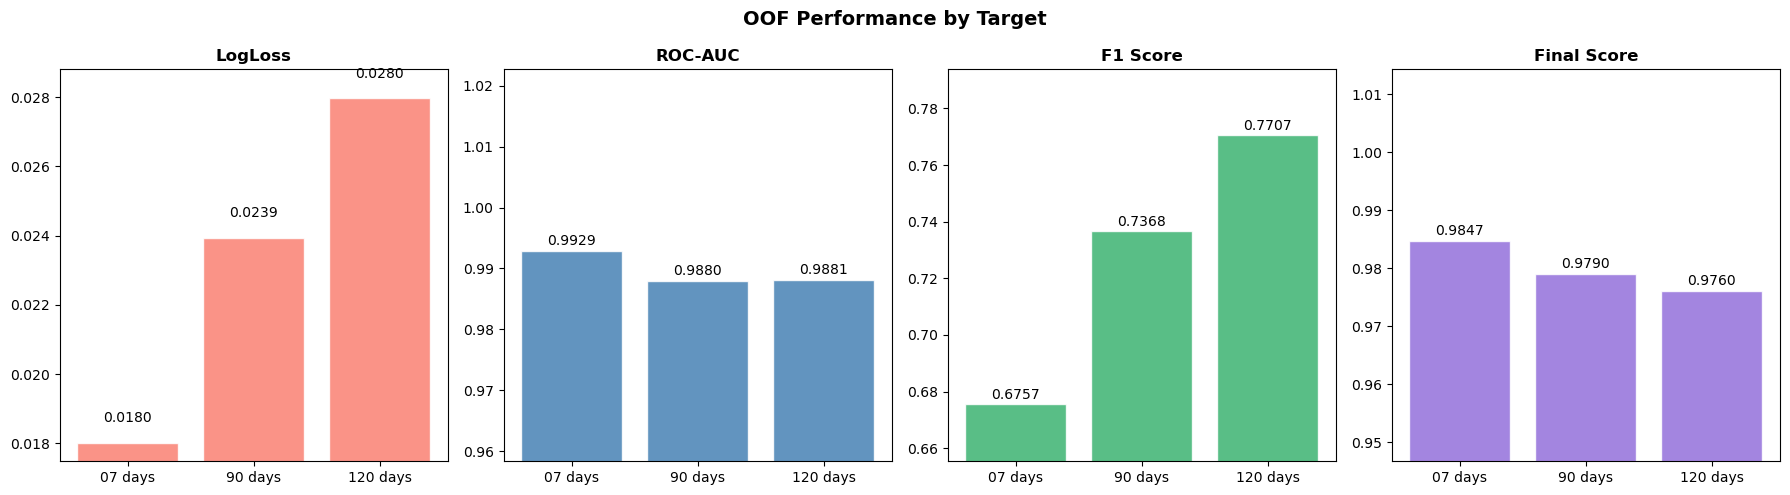

In [33]:
# OOF Final scores
labels = list(results.keys())
logloss_vals = [results[k]['logloss'] for k in labels]
auc_vals     = [results[k]['auc']     for k in labels]
f1_vals      = [results[k]['f1']      for k in labels]
scores       = [0.75*(1-results[k]['logloss']) + 0.25*results[k]['auc'] for k in labels]
short_labels = ['07 days', '90 days', '120 days']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
metrics_data = [
    (logloss_vals, 'LogLoss', 'salmon',   True),
    (auc_vals,     'ROC-AUC', 'steelblue', False),
    (f1_vals,      'F1 Score','mediumseagreen', False),
    (scores,       'Final Score', 'mediumpurple', False),
]

for ax, (vals, title, color, invert) in zip(axes, metrics_data):
    bars = ax.bar(short_labels, vals, color=color, alpha=0.85, edgecolor='white')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylim(min(vals)*0.97, max(vals)*1.03)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
                f'{v:.4f}', ha='center', va='bottom', fontsize=10)

plt.suptitle('OOF Performance by Target', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [36]:
# Save submission
submission.to_csv('submission_v5.csv', index=False)
print("submission_v5.csv saved")
submission.head()

submission_v5.csv saved


,ID,Target_07_AUC,Target_90_AUC,Target_120_AUC,Target_07_LogLoss,Target_90_LogLoss,Target_120_LogLoss
0,ID_LEG1GM,0.00100,0.00100,0.00100,0.00100,0.00100,0.00100
1,ID_1UKOKW,0.00100,0.00100,0.00100,0.00100,0.00100,0.00100
2,ID_U5H2YK,0.04698,0.04698,0.04698,0.04698,0.04698,0.04698
3,ID_55957A,0.04698,0.04698,0.04698,0.04698,0.04698,0.04698
4,ID_N1AC0A,0.00100,0.00100,0.00100,0.00100,0.00100,0.00100


# 16. Export PNGs

In [ ]:
import json, base64, os
with open('exploration.ipynb', 'r', encoding="utf-8") as f:
    nb = json.load(f)

os.makedirs('figures', exist_ok=True)

count = 0
for i, cell in enumerate(nb['cells']):
    for out in cell.get('outputs', []):
        data = out.get('data', {})
        if 'image/png' in data:
            with open(f'figures/fig_{i}_{count}.png', 'wb') as img:
                img.write(base64.b64decode(data['image/png']))
            count += 1

print(f"{count} pictures exported")


10 pictures exported
